# M07-2 | 同一張 Q/DQ 圖，經過三種處理各變成什麼 op

[![Open In Colab](https://colab.research.google.com/assets/colab-badge.svg)](https://colab.research.google.com/github/bobondemon/pt2e_quantize_and_deploy/blob/main/m07_representation_lowering/02_representation_and_lowering.ipynb)

到 M06 為止，`convert_pt2e` 的結果都是 Q/DQ 圖：運算仍是 fp32（conv2d、linear…），前後包著 quantize／dequantize，本身不會變快（M02-3）。
要變成整數運算，得有人把圖「改寫」。這本 notebook 拿同一張 Q/DQ 圖，看三種處理各做了什麼。三個名詞的定義與彼此的關係在 [M07 概覽](00_overview.ipynb)。

- **A.** 起點：Q/DQ 圖上的「dq → op → q」單元，後端要認出、要換成 int8 kernel 的就是這些。
- **B.** reference representation：`convert_pt2e(..., use_reference_representation=True)`。
- **C.** lowering：`lower_pt2e_quantized_to_x86`。
- **D.** Inductor：`torch.compile` 對 Q/DQ 圖做了什麼（用 profiler 看實際跑的 kernel）。

最後用一張總表比較 conv 單元在三種處理後變成什麼。

In [ ]:
#| include: false
# 在 Google Colab 上執行時：下載本教材的程式並安裝套件（第一次約需幾分鐘）。
# 在自己的電腦上執行時（環境見 README），這一格什麼都不做。
import sys

if "google.colab" in sys.modules:
    import os
    import subprocess

    repo = "/content/pt2e_quantize_and_deploy"
    if not os.path.exists(repo):
        subprocess.run(["git", "clone", "-q", "--depth", "1",
                        "https://github.com/bobondemon/pt2e_quantize_and_deploy.git", repo], check=True)
        subprocess.run([sys.executable, "-m", "pip", "install", "-q",
                        "--extra-index-url", "https://download.pytorch.org/whl/cpu",
                        "torch==2.14.0+cpu", "torchao==0.18.0", "onnx==1.23.0", "onnxscript==0.7.2",
                        "onnxruntime==1.30.0", "tabulate", "graphviz"], check=True)
    sys.path.insert(0, repo)  # 讓 notebook 能 import 本教材的 common/
    os.chdir(f"{repo}/m07_representation_lowering")

In [1]:
import copy
from collections import Counter

import torch

from common.data import calibration_batches, trained_tiny_net
from common.env import cpu_profile, env_summary
from common.graph_utils import QDQ_PREFIXES, diff_ops, op_counts, qdq_nodes, short
from common.models import example_inputs, get_model
from common.pt2e import convert_pt2e, export_module, get_xnnpack_quantizer, lower_pt2e_quantized_to_x86, prepare_pt2e, quiet
from common.viz import draw, table

quiet()
_ = torch.manual_seed(0)
QD = torch.ops.quantized_decomposed

**結果和平台有關**：A、B 是純粹的圖改寫，只隨 torch／torchao 的版本變；C、D 取決於機器（有沒有 mkldnn、conv 走哪個 kernel）。
下面存的輸出是在這個環境跑的；表格下的說明依實測印出：

In [2]:
print(env_summary())

Darwin arm64｜torch 2.14.0｜threads=4｜mkldnn=False｜nnpack=True


模型是 M05 的 `TinyConvNet`，用 XNNPACKQuantizer（per-channel weight）做 PTQ，得到 Q/DQ 圖：

In [3]:
def calibrated(model, per_channel=True):
    """export → prepare（XNNPACKQuantizer）→ 校準，回傳還沒 convert 的 prepared 圖。"""
    prepared = prepare_pt2e(export_module(model, example_inputs()), get_xnnpack_quantizer(is_per_channel=per_channel)[0])
    with torch.no_grad():
        for batch in calibration_batches(128):
            prepared(*batch)
    return prepared


model = trained_tiny_net()
qdq = convert_pt2e(calibrated(model))
(x,) = next(calibration_batches(16, seed=9))

## A. 起點：Q/DQ 圖上的「dq → op → q」單元

從每個 activation 的 quantize 往回走，走到 dequantize 為止，中間經過的 op 就是一個單元。
下面的 `qdq_units` 只認 XNNPACKQuantizer 產生的 per-tensor activation q/dq，不是通用的 pattern 偵測器：

In [4]:
def qdq_units(gm):
    """回傳 {單元的 op: (個數, 輸入與輸出的 (scale, zp) 是否全部相同)}。"""
    units, same = Counter(), {}
    for q in gm.graph.nodes:
        if q.target != QD.quantize_per_tensor.default:
            continue
        ops, in_qparams, frontier = [], set(), [q.args[0]]
        while frontier:
            n = frontier.pop()
            if n.target == QD.dequantize_per_tensor.default:
                in_qparams.add(tuple(n.args[1:3]))  # 輸入的 (scale, zp)
            if n.op != "call_function" or str(n.target).startswith(QDQ_PREFIXES):
                continue  # 走到 dequantize／quantize／placeholder／get_attr 就停
            ops.append(short(n.target))
            frontier += n.all_input_nodes
        if ops:
            key = " + ".join(reversed(ops))
            units[key] += 1
            same[key] = same.get(key, True) and in_qparams == {tuple(q.args[1:3])}
    return {k: (v, same[k]) for k, v in units.items()}


units = dict(sorted(qdq_units(qdq).items(), key=lambda kv: -kv[1][0]))
table([[k, n, "是" if s else "否"] for k, (n, s) in units.items()], ["dq → [op] → q 的 op", "個數", "輸入輸出同 qparams？"])

dq → [op] → q 的 op,個數,輸入輸出同 qparams？
conv2d + relu,3,否
max_pool2d,2,是
conv2d,1,否
add + relu,1,否
adaptive_avg_pool2d,1,是
flatten,1,是
linear,1,否


In [5]:
assert units["conv2d + relu"][0] >= 1 and not units["conv2d + relu"][1]
assert units["max_pool2d"][1]  # max_pool2d 的輸入輸出共用 qparams（M03-4）

以殘差 block 的 `add + relu` 單元為例：兩個 dequantize 進、一個 quantize 出，中間的 add、relu 都是 fp32：

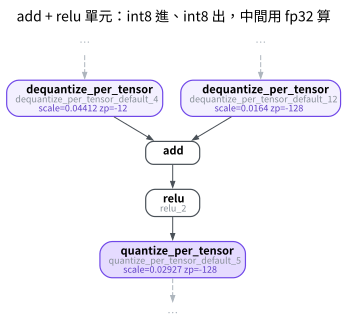

In [6]:
draw(qdq, focus=["add", "relu_2"], hops=1, title="add + relu 單元：int8 進、int8 出，中間用 fp32 算")

- 每個單元的語意都是「int8 進、int8 出，中間用 fp32 算」。後端要做的，是認出這些單元，換成自己的 int8 kernel（例如 conv2d + relu 換成一顆 int8 conv-relu）。
- Q/DQ 圖不綁任何後端：同一張圖可以交給 Inductor（本 notebook 的 C、D）、XNNPACK（M08）、ONNX Runtime（M09），各自用自己的 pattern 去認。這就是「Q/DQ 是後端中立的交換格式」的意思。
- **輸入輸出共用 qparams 的單元**（上表「是」的那幾種，M03-4 的 Shared）：整數 kernel 不必換 scale，max／flatten 直接搬 int8 值。
- **輸出 scale 和輸入不同的單元**：整數 kernel 最後要 requantize，把累加結果換到輸出的 scale。

## B. reference representation

`convert_pt2e(..., use_reference_representation=True)` 把 Q/DQ 寫成看得到的算術，並把對得上 torchao pattern 的單元改成整數運算。
先看最小的 conv_relu。下面兩張圖畫的是 conv 的輸入 x 進 conv2d 之前的那一段，node 底下是常數參數（scale、zp、dtype）：

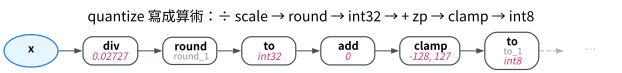

In [7]:
small = convert_pt2e(calibrated(get_model("conv_relu").eval()), use_reference_representation=True)


def literal(node):
    args = [a for a in node.args[1:] if not hasattr(a, "op")]
    if args:
        return ", ".join(f"{a:.4g}" if isinstance(a, float) else str(a).replace("torch.", "") for a in args)
    return str(node.kwargs.get("dtype", "")).replace("torch.", "")


chain, n = [], next(n for n in small.graph.nodes if n.name == "conv2d").args[0]
while n.op == "call_function":
    chain.append(n)
    n = n.args[0]
chain.reverse()  # x 之後的第一個 op 到 conv2d 之前
split = next(i for i, c in enumerate(chain) if torch.int8 in c.args) + 1  # 轉成 int8（to(int8)）為止是 quantize
quant_part, dequant_part = chain[:split], chain[split:]
notes = {c.name: literal(c) for c in chain}
draw(small, focus=["x"] + [c.name for c in quant_part], hops=0, notes=notes, rankdir="LR",
     title="quantize 寫成算術：÷ scale → round → int32 → + zp → clamp → int8")

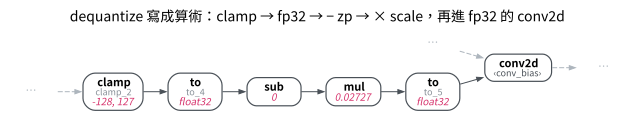

In [8]:
draw(small, focus=[c.name for c in dequant_part] + ["conv2d"], hops=0, notes=notes, rankdir="LR",
     title="dequantize 寫成算術：clamp → fp32 → − zp → × scale，再進 fp32 的 conv2d")

In [9]:
assert [short(c.target) for c in quant_part][:2] == ["div", "round"] and short(dequant_part[-2].target) == "mul"

quantize、dequantize 都變成一般的 ATen 算術，其中 `÷ scale`、`round`、`× scale` 仍是浮點運算：這一步是「把公式寫出來」，不是換成 int8 kernel。conv2d 本身沒變。

換到 `TinyConvNet`，比較 per-channel 與 per-tensor weight 兩種設定。torchao 把改成 int32 運算的 op 用 `out_dtype` 包起來，數它就知道哪些單元被改寫了：

In [10]:
def integer_ops(gm):
    """被 out_dtype（以 int32 計算）包起來的 op；out_dtype 的第一個參數就是被包的 op。"""
    return Counter(short(n.args[0]) for n in gm.graph.nodes if short(n.target) == "out_dtype")


b = {}
for label, per_channel in (("per-channel weight（預設）", True), ("per-tensor weight", False)):
    ref = convert_pt2e(calibrated(model, per_channel), use_reference_representation=True)
    c = op_counts(ref)
    b[label] = (sum(v for k, v in c.items() if k.startswith(("quantize", "dequantize"))), c["conv2d"], c["linear"],
                integer_ops(ref))
table([[k, q, cv, ln, ", ".join(f"{op}×{m}" for op, m in ints.items()) or "—"] for k, (q, cv, ln, ints) in b.items()],
      ["TinyConvNet", "剩下的 q/dq", "fp32 conv2d", "fp32 linear", "以 int32 計算的 op（out_dtype）"])

TinyConvNet,剩下的 q/dq,fp32 conv2d,fp32 linear,以 int32 計算的 op（out_dtype）
per-channel weight（預設）,0,4,1,mul×2
per-tensor weight,0,4,0,"mul×3, linear×1, div×1"


In [11]:
q_left, n_conv, _, _ = b["per-channel weight（預設）"]
assert q_left == 0 and n_conv == 4  # torchao 0.18：q/dq 全變算術，conv 沒被改寫
assert b["per-tensor weight"][2] == 0 and b["per-tensor weight"][3]["linear"] == 1  # per-tensor linear 改成整數

- q/dq 全部變成算術，一個都不剩。
- **conv2d 還在**，吃的是 dequantize 出來的 fp32：conv 單元沒有被改寫成整數運算。原因（讀 torchao 0.18 的 `reference_representation_rewrite.py`）：conv 的 pattern 用 `aten.convolution` 寫，`torch.export` 產生的是 `aten.conv2d`，對不上；pattern 只寫了 per-tensor weight，而且 conv 的輸出要直接接 quantize（中間不能有 relu）。三個條件都成立時整個單元會變成什麼，見 [M07 概覽](00_overview.ipynb)〈reference representation：把 Q/DQ 寫成明確的算術〉中「整個單元有沒有對上 pattern」那一段。
- **被改成整數運算的**：add + relu 的兩個輸入各用一個 int32 的 mul 換到輸出的 scale；per-tensor weight 時，linear 用 int32 累加、bias 用 div 量化、最後 mul 做 requantize。這類整數運算怎麼從 affine 量化公式推出來，見部落格〈[Quantization 的那些事](https://bobondemon.github.io/2020/10/03/Quantization-%E7%9A%84%E9%82%A3%E4%BA%9B%E4%BA%8B/#%E7%B4%94%E7%94%A8-Integer-%E9%81%8B%E7%AE%97)〉的〈純用 Integer 運算〉一節。

所以 reference representation 是「部分」改寫：q/dq 一定變算術，運算能不能變整數，要看 pattern 有沒有對上。

## C. lowering：`lower_pt2e_quantized_to_x86`

這個函式做三件事：重新 export 並 decompose（例如 conv2d → convolution）、跑 Inductor 的 freezing pass、constant folding。
x86 的 int8 pattern（例如 dq → conv → q 換成 `onednn.qconv_pointwise`）只在 mkldnn 可用時才註冊（概覽〈三者的關係〉）。下表是 lowering 前後的 op 增減：

In [12]:
lowered = lower_pt2e_quantized_to_x86(copy.deepcopy(qdq), (x,))
table(diff_ops(qdq, lowered, "Q/DQ 圖", "lowering 之後", tablefmt="html"))

op,Q/DQ 圖,lowering 之後,delta
adaptive_avg_pool2d,1,0,-1
addmm,0,1,1
conv2d,4,0,-4
convolution,0,4,4
flatten,1,0,-1
getitem,0,2,2
linear,1,0,-1
max_pool2d,2,0,-2
max_pool2d_with_indices,0,2,2
mean,0,1,1


In [13]:
onednn = Counter(short(n.target) for n in lowered.graph.nodes if "onednn" in str(n.target))
n_before, n_after = len(qdq_nodes(qdq)), len(qdq_nodes(lowered))
mkldnn = torch.backends.mkldnn.is_available()
print(f"onednn op：{dict(onednn) or '無'}；q/dq：{n_before} → {n_after}；mkldnn 可用：{mkldnn}")
if onednn:
    print(f"pattern 對上了：q/dq 從 {n_before} 個變成 {n_after} 個，這些單元換成了 oneDNN 的 int8 op。")
elif not mkldnn:
    print("沒有 mkldnn：pattern 沒有註冊，結果只是 decompose 過的 Q/DQ 圖，q/dq 一個都沒少。")
else:
    print("有 mkldnn 卻沒有 onednn op：pattern 有註冊但沒對上，請對照上方的 op 增減表（這裡沒有追查）。")
if not mkldnn:
    assert not onednn and n_after == n_before

onednn op：無；q/dq：28 → 28；mkldnn 可用：False
沒有 mkldnn：pattern 沒有註冊，結果只是 decompose 過的 Q/DQ 圖，q/dq 一個都沒少。


上表的增減大多是 decompose（`conv2d` → `convolution`、`linear` → `addmm` 等）。在沒有 mkldnn 的環境，lowering 只剩這一步；x86 上 lowering 後實際有哪些 op，這裡沒有驗證。

## D. Inductor：`torch.compile` 對 Q/DQ 圖做了什麼

`torch.compile` 產生的 kernel 不會以 ATen op 的名字出現在 profiler 裡，所以比較兩件事：q/dq 還有沒有以獨立的 kernel 被呼叫，以及 conv 實際走哪個 kernel。
profiler 用 M07-1 介紹過的 `cpu_profile()`：

In [14]:
CONV_WRAPPERS = ("aten::conv2d", "aten::convolution", "aten::_convolution", "aten::_nnpack_available")
INT8_HINTS = ("qconv", "onednn::q", "quantized::")  # 名稱含這些字就當成 int8 conv（推論，依 x86.py 的 op 名稱）


def kernel_calls(fn, x):
    """回傳 (q/dq 的 kernel 呼叫次數, conv 實際走的 kernel, op 呼叫總數)。"""
    with torch.no_grad():
        fn(x)  # 先跑一次：compile 在這裡編譯
        with cpu_profile() as prof:
            fn(x)
    names = [e.name for e in prof.events() or []]
    convs = sorted({s for s in names if "conv" in s and s not in CONV_WRAPPERS})
    return sum(s.startswith("quantized_decomposed::") for s in names), convs, sum("::" in s for s in names)


eager = kernel_calls(qdq, x)
try:
    compiled, compile_error = kernel_calls(torch.compile(copy.deepcopy(qdq)), x), None
except Exception as e:  # 例如 x86 + mkldnn：Inductor 把 max_pool2d 改寫成 run time 不能執行的 op
    compiled, compile_error = None, f"{type(e).__name__}: {str(e).splitlines()[0][:150]}"
table([[name, n, ", ".join(k), total] for name, r in (("Q/DQ 圖（eager）", eager), ("torch.compile(Q/DQ 圖)", compiled)) if r for n, k, total in [r]],
      ["", "q/dq 的 kernel 呼叫", "conv 實際走的 kernel", "op 呼叫總數"])

,q/dq 的 kernel 呼叫,conv 實際走的 kernel,op 呼叫總數
Q/DQ 圖（eager）,28,aten::_nnpack_spatial_convolution,526
torch.compile(Q/DQ 圖),0,aten::_nnpack_spatial_convolution,66


In [15]:
if compiled is None:
    is_int8 = False
    print(f"torch.compile 在這台機器上失敗，沒有可比較的結果：{compile_error}")
else:
    is_int8 = any(h in k for k in compiled[1] for h in INT8_HINTS)
    print(f"q/dq 的 kernel 呼叫：{eager[0]} → {compiled[0]}；op 呼叫：{eager[2]} → {compiled[2]}")
    print("conv：" + ("int8 kernel" if is_int8 else "仍是 fp32，沒有 int8 conv"))
    assert compiled[0] < eager[0]

q/dq 的 kernel 呼叫：28 → 0；op 呼叫：526 → 66
conv：仍是 fp32，沒有 int8 conv


- Inductor 把 dequantize、relu、quantize 這些逐元素運算融合進它產生的 kernel，所以 q/dq 不再是獨立的呼叫，op 呼叫次數也大幅減少。
- conv 是否變成 int8，看上面印出的結果。Inductor 的 freezing 設定預設是關的（概覽〈三者的關係〉），開了才會跑 C 段那些 int8 pattern 的 conv 改寫。
- 平台差異：在 x86 + mkldnn 上（torch 2.14，Linux x86_64），Inductor 的 x86 量化 pass 不論 freezing 開不開都會動手，而且會失敗：預設時 max_pool2d 被改寫成沒有 CPU 實作的 `aten::quantized_max_pool2d`（run time 報 `NotImplementedError`）；開 freezing 則在量化 conv 的 weight pack 時報 dtype 錯誤。這個 notebook 的儲存輸出來自 macOS arm64，那裡編譯正常（這些 x86 的量化 pass 不適用於 arm）；上面的 `try/except` 讓 notebook 在 x86 上也能跑完。

In [16]:
rows = [
    ["reference representation", "變成算術" if q_left == 0 else f"剩 {q_left} 個",
     f"fp32 conv2d（{n_conv} 個）" if n_conv else "整數 conv", "否" if n_conv else "是"],
    ["lower_pt2e_quantized_to_x86", "保留" if n_after == n_before else f"{n_before} → {n_after}",
     ", ".join(onednn) if onednn else "fp32 convolution", "是" if onednn else "否"],
    ["torch.compile", "compile 失敗" if compiled is None else "融進產生的 kernel" if compiled[0] == 0 else "部分保留",
     "—" if compiled is None else ", ".join(compiled[1]) or "—", "是" if is_int8 else "否"],
]
table(rows, ["處理", "q/dq", "conv", "conv 是整數運算？"])

處理,q/dq,conv,conv 是整數運算？
reference representation,變成算術,fp32 conv2d（4 個）,否
lower_pt2e_quantized_to_x86,保留,fp32 convolution,否
torch.compile,融進產生的 kernel,aten::_nnpack_spatial_convolution,否


In [17]:
n_int = sum(r[3] == "是" for r in rows)
print(f"有 {n_int} 種處理把 conv 變成整數運算。" if n_int else "三種處理都沒有把 conv 變成 int8 kernel。")

三種處理都沒有把 conv 變成 int8 kernel。


Q/DQ 圖只是「哪裡要量化、用什麼 qparams」的規格；真正的整數 kernel，要靠後端的 pattern 認出單元並替換。x86 需要 oneDNN；arm 上的路徑是 XNNPACK（M08）。
後端真正的 int8 kernel 和 Q/DQ 圖的數值差多少，M08、M09 再量。

## 小結

- Q/DQ 圖由「dq → op → q」單元組成，是後端中立的交換格式。
- reference representation 把 q/dq 寫成算術；運算要對上 torchao 的 pattern 才變成整數（torchao 0.18 的 conv 對不上）。
- lowering 與 `torch.compile` 要有後端的 int8 pattern 才會換 kernel；沒有時，lowering 只剩 decompose，`torch.compile` 只融合逐元素運算（在 x86 + mkldnn 上，Inductor 的量化 pass 反而可能讓編譯失敗，見 D 段）。